# Exercise8.04: Animated aircraft custom layer

LU MENGJIE - MC643920

CARTO now requires an API key. With user approval, Esri public light/dark gray tiles replace CARTO, while the custom HOT provider is retained. The bundled official Geoplotlib source has Python 3 / NumPy / SciPy compatibility fixes; it is not a replacement plotting library.

## Exercise8.04 - 01. Read aircraft observations

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('../../Support').resolve()))
import course_maps
import geoplotlib
import pandas as pd
import numpy as np
from geoplotlib.utils import DataAccessObject, BoundingBox, read_csv
from IPython.display import display
DATA = Path('../../Datasets')
print('LU MENGJIE | MC643920 | Suggested Exercise 08')
print('Public Esri gray basemaps replace key-protected CARTO; HOT is the custom provider.')
dataset=pd.read_csv(DATA/'flight_tracking.csv')
print('Observations:',len(dataset))
display(dataset.head())

LU MENGJIE | MC643920 | Suggested Exercise 08
Public Esri gray basemaps replace key-protected CARTO; HOT is the custom provider.
Observations: 33766


,hex_ident,altitude(feet),latitude,longitude,date,time,angle,distance(nauticalmile),squawk,ground_speed(knotph),track,callsign
0,40631C,14525,53.65947,-1.43819,2017/09/11,17:02:06.418,-120.77,11.27,6276.0,299.0,283.0,NaN
1,40631C,14525,53.65956,-1.43921,2017/09/11,17:02:06.875,-120.64,11.30,6276.0,299.0,283.0,NaN
2,40631C,14500,53.65979,-1.44066,2017/09/11,17:02:07.342,-120.43,11.32,6276.0,299.0,283.0,EZY63BT
3,40631C,14475,53.66025,-1.44447,2017/09/11,17:02:09.238,-119.94,11.40,6276.0,299.0,283.0,EZY63BT
4,40631C,14475,53.66044,-1.44591,2017/09/11,17:02:09.825,-119.75,11.43,6276.0,299.0,283.0,EZY63BT


## Exercise8.04 - 02. Rename coordinates and create timestamps

In [2]:
from datetime import datetime
dataset=dataset.rename(columns={'latitude':'lat','longitude':'lon'})
display(dataset.head())
def to_epoch(date,time):
    return round(datetime.strptime(f'{date} {time}','%Y/%m/%d %H:%M:%S.%f').timestamp())
dataset['timestamp']=dataset.apply(lambda x:to_epoch(x['date'],x['time']),axis=1)
display(dataset[['hex_ident','lat','lon','date','time','timestamp']].head())
print('Invalid timestamps:',dataset.timestamp.isna().sum())

,hex_ident,altitude(feet),lat,lon,date,time,angle,distance(nauticalmile),squawk,ground_speed(knotph),track,callsign
0,40631C,14525,53.65947,-1.43819,2017/09/11,17:02:06.418,-120.77,11.27,6276.0,299.0,283.0,NaN
1,40631C,14525,53.65956,-1.43921,2017/09/11,17:02:06.875,-120.64,11.30,6276.0,299.0,283.0,NaN
2,40631C,14500,53.65979,-1.44066,2017/09/11,17:02:07.342,-120.43,11.32,6276.0,299.0,283.0,EZY63BT
3,40631C,14475,53.66025,-1.44447,2017/09/11,17:02:09.238,-119.94,11.40,6276.0,299.0,283.0,EZY63BT
4,40631C,14475,53.66044,-1.44591,2017/09/11,17:02:09.825,-119.75,11.43,6276.0,299.0,283.0,EZY63BT


,hex_ident,lat,lon,date,time,timestamp
0,40631C,53.65947,-1.43819,2017/09/11,17:02:06.418,1505120526
1,40631C,53.65956,-1.43921,2017/09/11,17:02:06.875,1505120527
2,40631C,53.65979,-1.44066,2017/09/11,17:02:07.342,1505120527
3,40631C,53.66025,-1.44447,2017/09/11,17:02:09.238,1505120529
4,40631C,53.66044,-1.44591,2017/09/11,17:02:09.825,1505120530


Invalid timestamps: 0


## Exercise8.04 - 03. Define TrackLayer

In [3]:
from geoplotlib.layers import BaseLayer
from geoplotlib.core import BatchPainter
from geoplotlib.colors import colorbrewer
from geoplotlib.utils import epoch_to_str
class TrackLayer(BaseLayer):
    def __init__(self,dataset,bbox=BoundingBox.WORLD):
        self.data=dataset
        self.cmap=colorbrewer(self.data['hex_ident'],alpha=200)
        self.time=self.data['timestamp'].min()
        self.painter=BatchPainter()
        self.view=bbox
    def draw(self,proj,mouse_x,mouse_y,ui_manager):
        self.painter=BatchPainter()
        df=self.data.where((self.data['timestamp'] > self.time) &
                           (self.data['timestamp'] <= self.time+180))
        for element in sorted(set(df['hex_ident'])):
            grp=df.where(df['hex_ident']==element)
            self.painter.set_color(self.cmap[element])
            x,y=proj.lonlat_to_screen(grp['lon'],grp['lat'])
            self.painter.points(x,y,15,rounded=True)
        self.painter.batch_draw()
        ui_manager.info('Current timestamp: '+epoch_to_str(self.time))
        self.time+=1
        if self.time > self.data['timestamp'].max():
            self.time=self.data['timestamp'].min()
    def bbox(self):
        return self.view

## Exercise8.04 - 04. Leeds view and live animation

Preview starts at observed busy interval: 2017-09-12 09:51 local time


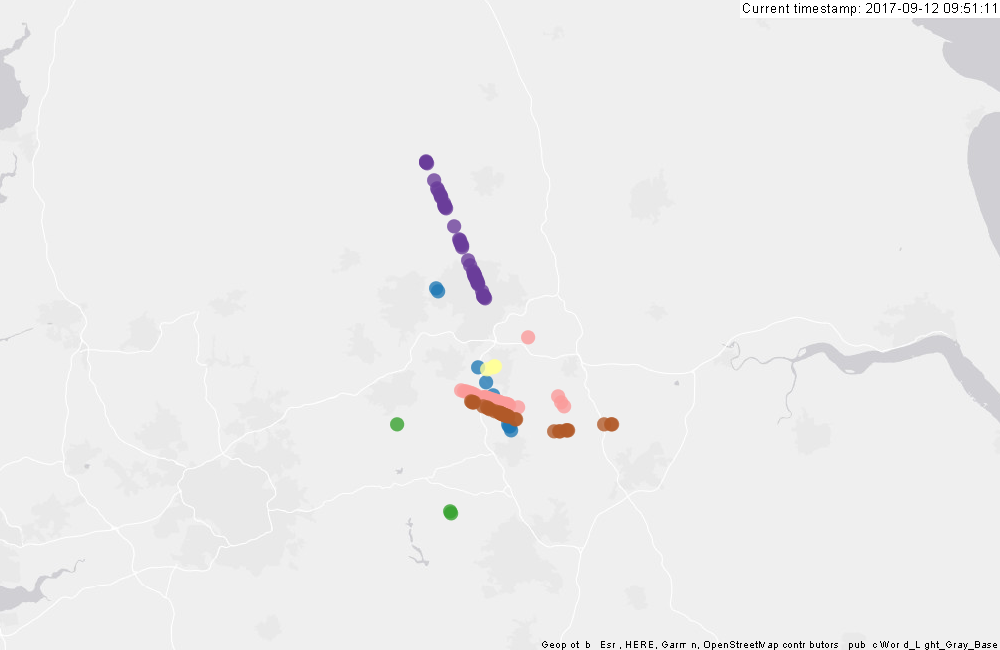

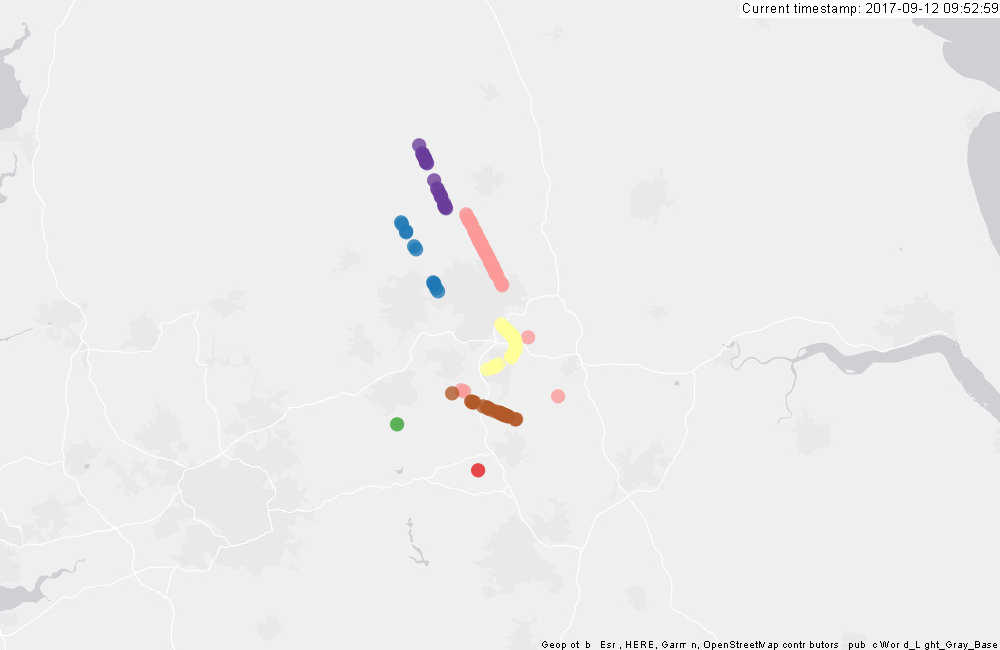

Saved real rendered animation: outputs/aircraft_motion.gif | distinct frames: 10


In [4]:
leeds_bbox=BoundingBox(north=53.8074,west=-3,south=53.7074,east=0)
data=DataAccessObject(dataset)
layer=TrackLayer(data,bbox=leeds_bbox)
# Preview a real busy interval; TrackLayer itself still initializes at the first timestamp.
layer.time=round(datetime(2017,9,12,9,51).timestamp())
print('Preview starts at observed busy interval: 2017-09-12 09:51 local time')
geoplotlib.add_layer(layer)
course_maps.animation('aircraft_motion',layer)
# To interact with the window manually: geoplotlib.add_layer(TrackLayer(data,leeds_bbox)); geoplotlib.show()